r cloud/limmag: -0.12370458223919642
                         rad       lim    n
site_id                                    
sommers_bausch     64.848410  2.476021  563
denver_downtown   165.271538  2.747664  321
boulder_downtown   45.012311  2.815029  346
ncar_mesa           6.035833  2.943820   89
golden_gate_sp      0.000000  3.611111   18
flagstaff_mtn       0.998296  3.905325  169
longmont           45.442016  3.910959  146
gross_reservoir     9.527162  4.422819  149
lyons               8.192628  4.423077   26
nederland           6.693327  4.607143   56
crestone            1.191272  6.103825  183
                                     mean  count
illum_bin      moon_state                       
(-0.001, 0.25] Moon mostly down  3.302602   1345
(0.25, 0.5]    Moon mostly down  3.491749    303
               Moon up           3.459459     74
(0.5, 0.75]    Moon mostly down  3.352941     51
               Moon up           3.732394    142
(0.75, 1.0]    Moon up           3.456647    173

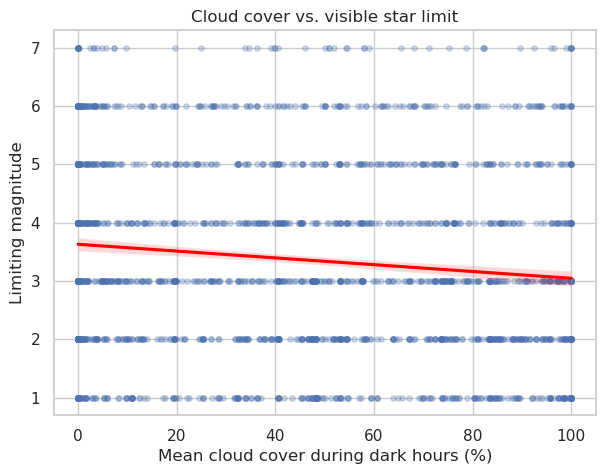

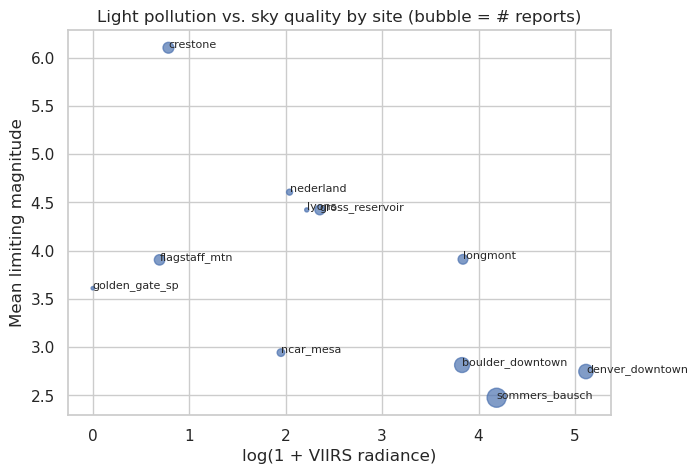

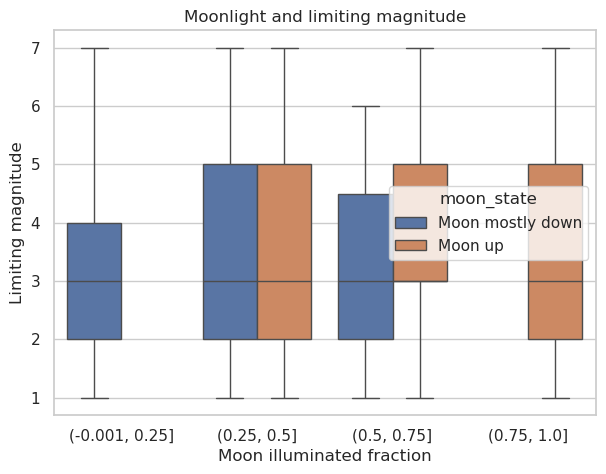

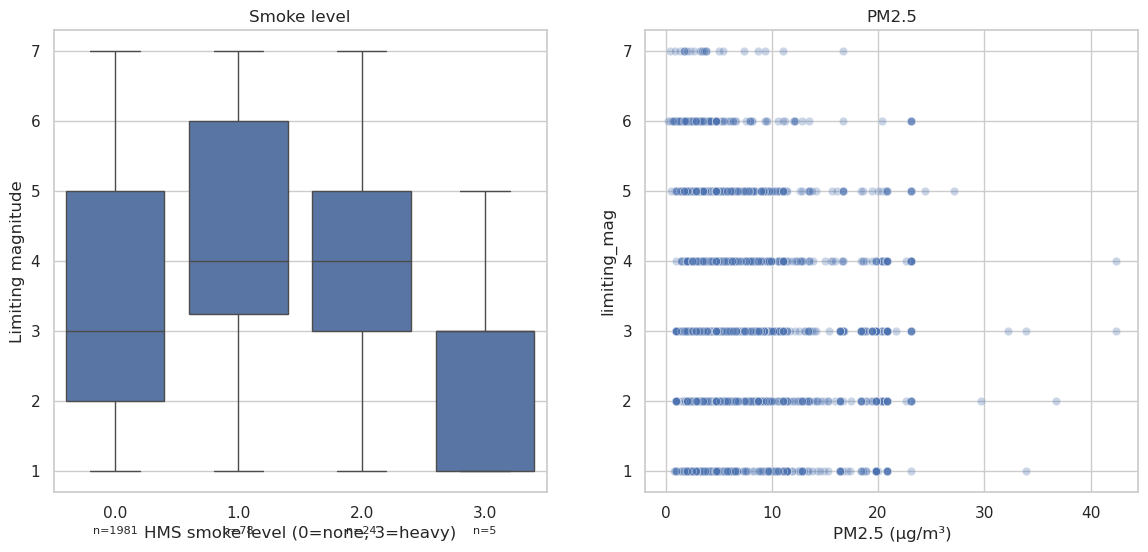

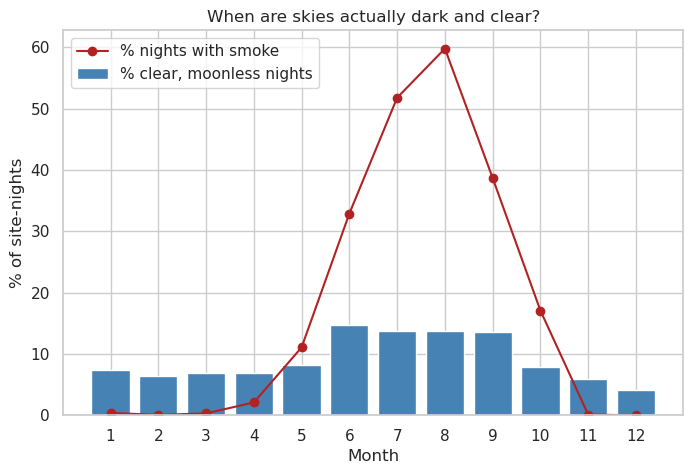

In [2]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

P = "../processed/"
d1 = pd.read_csv(P + "dataset1_site_night_cleaned.csv", parse_dates=["night_date"])
d2 = pd.read_csv(P + "dataset2_gan_observations_cleaned.csv", parse_dates=["night_date"])
d2 = d2[d2["matched"] == True].dropna(subset=["limiting_mag"])
sns.set_theme(style="whitegrid")

# 1. Cloud cover vs limiting magnitude (does weather limit what observers see?)
fig, ax = plt.subplots(figsize=(7,5))
sns.regplot(data=d2, x="cloud_cover_mean", y="limiting_mag",
            scatter_kws={"alpha":.25, "s":15}, line_kws={"color":"red"}, ax=ax)
ax.set(xlabel="Mean cloud cover during dark hours (%)", ylabel="Limiting magnitude",
       title="Cloud cover vs. visible star limit")
fig.savefig("fig1_cloud_vs_limmag.png", dpi=200, bbox_inches="tight")
print("r cloud/limmag:", d2[["cloud_cover_mean","limiting_mag"]].corr().iloc[0,1])

# 2. Light pollution (VIIRS) vs limiting magnitude, by site
site = d2.groupby("site_id").agg(rad=("viirs_radiance","mean"),
        lim=("limiting_mag","mean"), n=("limiting_mag","size")).query("n>=10")
fig, ax = plt.subplots(figsize=(7,5))
ax.scatter(np.log1p(site.rad), site.lim, s=site.n/3, alpha=.7)
for s, r in site.iterrows(): ax.annotate(s, (np.log1p(r.rad), r.lim), fontsize=8)
ax.set(xlabel="log(1 + VIIRS radiance)", ylabel="Mean limiting magnitude",
       title="Light pollution vs. sky quality by site (bubble = # reports)")
fig.savefig("fig2_radiance_vs_limmag.png", dpi=200, bbox_inches="tight")
print(site.sort_values("lim"))

# 3. Moon illumination effect (moon up vs. down)
d2["moon_state"] = np.where(d2.moon_up_frac > .5, "Moon up", "Moon mostly down")
d2["illum_bin"] = pd.cut(d2.moon_illum_frac, [0,.25,.5,.75,1], include_lowest=True)
fig, ax = plt.subplots(figsize=(7,5))
sns.boxplot(data=d2, x="illum_bin", y="limiting_mag", hue="moon_state", ax=ax)
ax.set(xlabel="Moon illuminated fraction", ylabel="Limiting magnitude",
       title="Moonlight and limiting magnitude")
fig.savefig("fig3_moon.png", dpi=200, bbox_inches="tight")
print(d2.groupby(["illum_bin","moon_state"], observed=True).limiting_mag.agg(["mean","count"]))

# 4. Smoke / PM2.5 vs limiting magnitude (small n: show counts)
fig, axes = plt.subplots(1, 2, figsize=(14,6))
sns.boxplot(data=d2, x="hms_smoke_level", y="limiting_mag", ax=axes[0])
axes[0].set(xlabel="HMS smoke level (0=none, 3=heavy)", ylabel="Limiting magnitude",
            title="Smoke level")
for i, n in enumerate(d2.groupby("hms_smoke_level").size()):
    axes[0].text(i, 0.1, f"n={n}", ha="center", fontsize=8)
sns.scatterplot(data=d2, x="pm25_ugm3", y="limiting_mag", alpha=.3, ax=axes[1])
axes[1].set(xlabel="PM2.5 (µg/m³)", title="PM2.5")
fig.savefig("fig4_smoke_pm25.png", dpi=200, bbox_inches="tight")
print(d2.groupby("hms_smoke_level").limiting_mag.agg(["mean","count"]))

# 5. Seasonal pattern: share of clear, moonless nights by month (Dataset 1) vs. smoke
d1["month"] = d1.night_date.dt.month
d1["good"] = (d1.cloud_cover_mean < 20) & (d1.moon_up_frac < .1)
m = d1.groupby("month").agg(good=("good","mean"), smoke=("hms_smoke_level", lambda s:(s>0).mean()))
fig, ax = plt.subplots(figsize=(8,5))
ax.bar(m.index, m.good*100, color="steelblue", label="% clear, moonless nights")
ax.plot(m.index, m.smoke*100, color="firebrick", marker="o", label="% nights with smoke")
ax.set(xlabel="Month", ylabel="% of site-nights", xticks=range(1,13),
       title="When are skies actually dark and clear?")
ax.legend()
fig.savefig("fig5_seasonality.png", dpi=200, bbox_inches="tight")
print(m.round(3))

                     mean  count
hms_smoke_level                 
0.0             -0.017493   1981
1.0              0.424303     78
2.0              0.192613     24
3.0             -0.612982      5


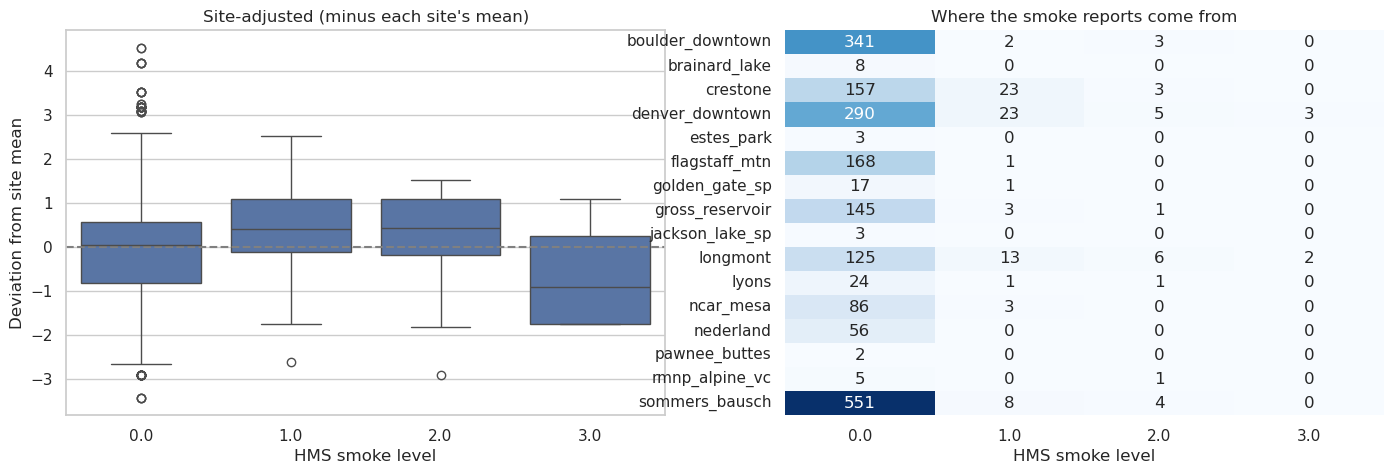

In [8]:
# 6. Smoke effect after removing site differences
d2["lim_site_dev"] = d2.limiting_mag - d2.groupby("site_id").limiting_mag.transform("mean")

fig, axes = plt.subplots(1, 2, figsize=(17, 5))
sns.boxplot(data=d2, x="hms_smoke_level", y="lim_site_dev", ax=axes[0])
axes[0].axhline(0, color="gray", ls="--")
axes[0].set(title="Site-adjusted (minus each site's mean)", xlabel="HMS smoke level",
            ylabel="Deviation from site mean")

ct = pd.crosstab(d2.site_id, d2.hms_smoke_level)
sns.heatmap(ct, annot=True, fmt="d", cmap="Blues", cbar=False, ax=axes[1])
axes[1].set(title="Where the smoke reports come from", xlabel="HMS smoke level", ylabel="")

fig.savefig("fig6_smoke_site_adjusted.png", dpi=200, bbox_inches="tight")
print(d2.groupby("hms_smoke_level").lim_site_dev.agg(["mean", "count"]))